# Explorative Data Analysis

In this notebook, we will have a closer look on the energy production data of Germany between 2015 - 2025 provided by SMARD.
The goal is to observe how energy production developed over the years in Germany, especially the development of the different methods of energy production. 

## 1. Raw Data

In [1]:
import pandas as pd
import sys
import matplotlib.pyplot as plt

In [2]:
df_raw = pd.read_csv("../data/raw/Realisierte_Erzeugung_201501010000_202601010000_Monat.csv")
df_raw.head()

,,,,,,,,,,,,Datum von;Datum bis;Biomasse [MWh] Berechnete Auflösungen;Wasserkraft [MWh] Berechnete Auflösungen;Wind Offshore [MWh] Berechnete Auflösungen;Wind Onshore [MWh] Berechnete Auflösungen;Photovoltaik [MWh] Berechnete Auflösungen;Sonstige Erneuerbare [MWh] Berechnete Auflösungen;Kernenergie [MWh] Berechnete Auflösungen;Braunkohle [MWh] Berechnete Auflösungen;Steinkohle [MWh] Berechnete Auflösungen;Erdgas [MWh] Berechnete Auflösungen;Pumpspeicher [MWh] Berechnete Auflösungen;Sonstige Konventionelle [MWh] Berechnete Auflösungen
01.01.2015;01.02.2015;3.479.938,77;1.186.617,59;264.490,14;9.404.178,83;560.194,61;175.611,97;8.201.762,38;11.800.183,18;6.387.685,58;1.405.688,92;762.023,04;839.702,19.0
01.02.2015;01.03.2015;3.153.613,46;871.004,80;284.790,22;5.181.228,19;1.367.809,39;154.664,97;7.498.808,73;11.249.755,30;7.886.895,71;1.615.352,60;651.887,77;797.723,97.0
01.03.2015;01.04.2015;3.437.602,13;1.030.917,99;434.443,05;6.865.747,54;2.839.770,88;156.243,35;7.308.641,32;12.177.183,02;7.320.063,65;1.359.908,55;718.934,49;817.338,79.0
01.04.2015;01.05.2015;3.269.723,30;1.248.928,32;379.940,40;4.837.677,66;4.380.466,76;151.245,19;6.858.356,45;10.200.743,22;5.994.324,95;850.196,84;676.779,64;770.986,52.0
01.05.2015;01.06.2015;3.361.025,36;1.560.655,41;566.551,40;4.848.138,13;4.366.740,00;136.081,97;6.930.784,48;8.935.798,05;4.295.091,75;866.135,02;747.062,94;714.053,44.0


The columns in the csv-file are separated with ";". This leads into a data frame with only one column. The code needs to be adjusted, so that the columns can be separated as intended.

In [3]:
df_raw2 = pd.read_csv("../data/raw/Realisierte_Erzeugung_201501010000_202601010000_Monat.csv", sep=";")
df_raw2.head()

,Datum von,Datum bis,Biomasse [MWh] Berechnete Auflösungen,Wasserkraft [MWh] Berechnete Auflösungen,Wind Offshore [MWh] Berechnete Auflösungen,Wind Onshore [MWh] Berechnete Auflösungen,Photovoltaik [MWh] Berechnete Auflösungen,Sonstige Erneuerbare [MWh] Berechnete Auflösungen,Kernenergie [MWh] Berechnete Auflösungen,Braunkohle [MWh] Berechnete Auflösungen,Steinkohle [MWh] Berechnete Auflösungen,Erdgas [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Sonstige Konventionelle [MWh] Berechnete Auflösungen
0,01.01.2015,01.02.2015,"3.479.938,77","1.186.617,59","264.490,14","9.404.178,83","560.194,61","175.611,97","8.201.762,38","11.800.183,18","6.387.685,58","1.405.688,92","762.023,04","839.702,19"
1,01.02.2015,01.03.2015,"3.153.613,46","871.004,80","284.790,22","5.181.228,19","1.367.809,39","154.664,97","7.498.808,73","11.249.755,30","7.886.895,71","1.615.352,60","651.887,77","797.723,97"
2,01.03.2015,01.04.2015,"3.437.602,13","1.030.917,99","434.443,05","6.865.747,54","2.839.770,88","156.243,35","7.308.641,32","12.177.183,02","7.320.063,65","1.359.908,55","718.934,49","817.338,79"
3,01.04.2015,01.05.2015,"3.269.723,30","1.248.928,32","379.940,40","4.837.677,66","4.380.466,76","151.245,19","6.858.356,45","10.200.743,22","5.994.324,95","850.196,84","676.779,64","770.986,52"
4,01.05.2015,01.06.2015,"3.361.025,36","1.560.655,41","566.551,40","4.848.138,13","4.366.740,00","136.081,97","6.930.784,48","8.935.798,05","4.295.091,75","866.135,02","747.062,94","714.053,44"


In [4]:
df_raw2.tail()

,Datum von,Datum bis,Biomasse [MWh] Berechnete Auflösungen,Wasserkraft [MWh] Berechnete Auflösungen,Wind Offshore [MWh] Berechnete Auflösungen,Wind Onshore [MWh] Berechnete Auflösungen,Photovoltaik [MWh] Berechnete Auflösungen,Sonstige Erneuerbare [MWh] Berechnete Auflösungen,Kernenergie [MWh] Berechnete Auflösungen,Braunkohle [MWh] Berechnete Auflösungen,Steinkohle [MWh] Berechnete Auflösungen,Erdgas [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Sonstige Konventionelle [MWh] Berechnete Auflösungen
127,01.08.2025,01.09.2025,"2.852.499,35","1.463.011,45","1.699.077,95","5.459.159,51","9.672.278,48","73.973,16",-,"4.518.747,75","1.301.445,00","3.015.974,75","843.045,25","1.075.939,50"
128,01.09.2025,01.10.2025,"2.794.210,42","1.208.876,63","2.410.541,28","9.721.142,41","6.435.895,39","72.157,99",-,"4.925.688,75","1.397.569,00","3.790.773,75","733.651,25","1.014.139,00"
129,01.10.2025,01.11.2025,"3.034.056,45","1.116.769,65","2.901.834,16","13.695.534,40","3.642.622,45","79.788,30",-,"5.648.721,13","2.166.156,53","5.275.413,52","756.737,01","1.394.098,94"
130,01.11.2025,01.12.2025,"3.069.622,61","1.084.135,10","2.716.300,26","9.952.192,85","2.210.900,10","81.528,93",-,"6.595.504,11","3.165.924,61","7.519.788,06","673.562,25","1.350.662,80"
131,01.12.2025,01.01.2026,"3.193.590,01","1.022.205,69","3.425.383,69","12.474.033,51","1.509.063,85","88.217,82",-,"5.444.634,18","2.599.886,52","7.523.775,97","719.716,35","1.429.378,01"


In [5]:
df_raw2.describe()

,Datum von,Datum bis,Biomasse [MWh] Berechnete Auflösungen,Wasserkraft [MWh] Berechnete Auflösungen,Wind Offshore [MWh] Berechnete Auflösungen,Wind Onshore [MWh] Berechnete Auflösungen,Photovoltaik [MWh] Berechnete Auflösungen,Sonstige Erneuerbare [MWh] Berechnete Auflösungen,Kernenergie [MWh] Berechnete Auflösungen,Braunkohle [MWh] Berechnete Auflösungen,Steinkohle [MWh] Berechnete Auflösungen,Erdgas [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Sonstige Konventionelle [MWh] Berechnete Auflösungen
count,132,132,132,132,132,132,132,132,132,132,132,132,132,132
unique,132,132,132,132,132,132,132,132,102,132,132,132,132,132
top,01.01.2015,01.02.2015,"3.479.938,77","1.186.617,59","264.490,14","9.404.178,83","560.194,61","175.611,97",-,"11.800.183,18","6.387.685,58","1.405.688,92","762.023,04","839.702,19"
freq,1,1,1,1,1,1,1,1,24,1,1,1,1,1


#### First Impressions

1. Each row showcases the amount of energy that has been produced in that month. 2 columns give the timeframe of said production: First and last day of the month in the given year.
2. Since provided data is from SMARD, default language is German.
3. Numbers for energy production are separated every thousandth digit with a ".". Decimals are separated with ",".
4. The available energy productions can be separated into 2 groups: Renewable and conventional energy.
5. For "Kernenergie", there are no values in the last 5 rows. This needs to be looked at further.
6. There are columns for other production methods -> "Sonstige Konventionelle" and "Sonstige Erneuerbare". They contain multiple smaller producer which they are to small on their own. That's why they are grouped together.
7. Since number columns are still stored as text (due to the German decimal format), describe() doesn't provide meaningful statistics yet.

In [6]:
df_raw2[["Datum von", "Kernenergie [MWh] Berechnete Auflösungen"]]

,Datum von,Kernenergie [MWh] Berechnete Auflösungen
0,01.01.2015,"8.201.762,38"
1,01.02.2015,"7.498.808,73"
2,01.03.2015,"7.308.641,32"
3,01.04.2015,"6.858.356,45"
4,01.05.2015,"6.930.784,48"
...,...,...
127,01.08.2025,-
128,01.09.2025,-
129,01.10.2025,-
130,01.11.2025,-


Starting May/2023, nuclear energy production is 0. It also gets changed into a "-" starting the year 2024. The reason for this is that Germany decided on June 30 2011 to exit from nuclear energy prodcution completely after the catastrophe in Fukushima/Japan on March 11 2011. The last 3 nuclear reactors were shut down on April 15 2023.

In [7]:
df_raw2.isna().sum()

Datum von                                               0
Datum bis                                               0
Biomasse [MWh] Berechnete Auflösungen                   0
Wasserkraft [MWh] Berechnete Auflösungen                0
Wind Offshore [MWh] Berechnete Auflösungen              0
Wind Onshore [MWh] Berechnete Auflösungen               0
Photovoltaik [MWh] Berechnete Auflösungen               0
Sonstige Erneuerbare [MWh] Berechnete Auflösungen       0
Kernenergie [MWh] Berechnete Auflösungen                0
Braunkohle [MWh] Berechnete Auflösungen                 0
Steinkohle [MWh] Berechnete Auflösungen                 0
Erdgas [MWh] Berechnete Auflösungen                     0
Pumpspeicher [MWh] Berechnete Auflösungen               0
Sonstige Konventionelle [MWh] Berechnete Auflösungen    0
dtype: int64

There doesn't seem to be any missing data. But since "-" isn't designated as na-value, the code falsely makes the assumption that there are no missing data.

In [8]:
df_raw3 = pd.read_csv("../data/raw/Realisierte_Erzeugung_201501010000_202601010000_Monat.csv", sep=";", na_values="-")
df_raw3.isna().sum()

Datum von                                                0
Datum bis                                                0
Biomasse [MWh] Berechnete Auflösungen                    0
Wasserkraft [MWh] Berechnete Auflösungen                 0
Wind Offshore [MWh] Berechnete Auflösungen               0
Wind Onshore [MWh] Berechnete Auflösungen                0
Photovoltaik [MWh] Berechnete Auflösungen                0
Sonstige Erneuerbare [MWh] Berechnete Auflösungen        0
Kernenergie [MWh] Berechnete Auflösungen                24
Braunkohle [MWh] Berechnete Auflösungen                  0
Steinkohle [MWh] Berechnete Auflösungen                  0
Erdgas [MWh] Berechnete Auflösungen                      0
Pumpspeicher [MWh] Berechnete Auflösungen                0
Sonstige Konventionelle [MWh] Berechnete Auflösungen     0
dtype: int64

Now it is certain, that "Kernenergie" has missing values because of the "-". It correctly shows 24 missing values.

# 2. Processed Data

In order to make the data more usable, a script was made which does the following:

- when reading csv from SMARD -> separate columns with ";", include "-" as na-value (as was already done above)
- remove "Berechnete Auflösungen" from the columns to have shorter and more comprehensible column names
- change the structure of the numbers so that "." does not separate every thousandth digit and instead separates the decimals
- New columns for Month and Year for better grouping, removed the column "Datum bis"
- translate the German column names to English (e.g. "Braunkohle" -> "Lignite"), so the project uses one language


The columns for the energy production were also duplicated with [TWh] as unit. But this change will be more relevant for visualization purposes in the analysis notebook.

In [9]:
sys.path.append("../src")

In [10]:
from clean_smard_data import clean_smard_export

df = clean_smard_export("../data/raw/Realisierte_Erzeugung_201501010000_202601010000_Monat.csv")

In [11]:
df.head()

,Date,Year,Month,Biomass [MWh],Hydropower [MWh],Wind Offshore [MWh],Wind Onshore [MWh],Photovoltaics [MWh],Other Renewables [MWh],Nuclear [MWh],...,Wind Offshore [TWh],Wind Onshore [TWh],Photovoltaics [TWh],Other Renewables [TWh],Nuclear [TWh],Lignite [TWh],Hard Coal [TWh],Natural Gas [TWh],Pumped Storage [TWh],Other Conventional [TWh]
0,2015-01-01,2015,January,3479938.77,1186617.59,264490.14,9404178.83,560194.61,175611.97,8201762.38,...,0.264490,9.404179,0.560195,0.175612,8.201762,11.800183,6.387686,1.405689,0.762023,0.839702
1,2015-02-01,2015,February,3153613.46,871004.80,284790.22,5181228.19,1367809.39,154664.97,7498808.73,...,0.284790,5.181228,1.367809,0.154665,7.498809,11.249755,7.886896,1.615353,0.651888,0.797724
2,2015-03-01,2015,March,3437602.13,1030917.99,434443.05,6865747.54,2839770.88,156243.35,7308641.32,...,0.434443,6.865748,2.839771,0.156243,7.308641,12.177183,7.320064,1.359909,0.718934,0.817339
3,2015-04-01,2015,April,3269723.30,1248928.32,379940.40,4837677.66,4380466.76,151245.19,6858356.45,...,0.379940,4.837678,4.380467,0.151245,6.858356,10.200743,5.994325,0.850197,0.676780,0.770987
4,2015-05-01,2015,May,3361025.36,1560655.41,566551.40,4848138.13,4366740.00,136081.97,6930784.48,...,0.566551,4.848138,4.366740,0.136082,6.930784,8.935798,4.295092,0.866135,0.747063,0.714053


In [12]:
df.tail()

,Date,Year,Month,Biomass [MWh],Hydropower [MWh],Wind Offshore [MWh],Wind Onshore [MWh],Photovoltaics [MWh],Other Renewables [MWh],Nuclear [MWh],...,Wind Offshore [TWh],Wind Onshore [TWh],Photovoltaics [TWh],Other Renewables [TWh],Nuclear [TWh],Lignite [TWh],Hard Coal [TWh],Natural Gas [TWh],Pumped Storage [TWh],Other Conventional [TWh]
127,2025-08-01,2025,August,2852499.35,1463011.45,1699077.95,5459159.51,9672278.48,73973.16,0.0,...,1.699078,5.459160,9.672278,0.073973,0.0,4.518748,1.301445,3.015975,0.843045,1.075940
128,2025-09-01,2025,September,2794210.42,1208876.63,2410541.28,9721142.41,6435895.39,72157.99,0.0,...,2.410541,9.721142,6.435895,0.072158,0.0,4.925689,1.397569,3.790774,0.733651,1.014139
129,2025-10-01,2025,October,3034056.45,1116769.65,2901834.16,13695534.40,3642622.45,79788.30,0.0,...,2.901834,13.695534,3.642622,0.079788,0.0,5.648721,2.166157,5.275414,0.756737,1.394099
130,2025-11-01,2025,November,3069622.61,1084135.10,2716300.26,9952192.85,2210900.10,81528.93,0.0,...,2.716300,9.952193,2.210900,0.081529,0.0,6.595504,3.165925,7.519788,0.673562,1.350663
131,2025-12-01,2025,December,3193590.01,1022205.69,3425383.69,12474033.51,1509063.85,88217.82,0.0,...,3.425384,12.474034,1.509064,0.088218,0.0,5.444634,2.599887,7.523776,0.719716,1.429378


Column names are shorter now. Year and month are also included now.

In [13]:
df.describe()

,Date,Year,Biomass [MWh],Hydropower [MWh],Wind Offshore [MWh],Wind Onshore [MWh],Photovoltaics [MWh],Other Renewables [MWh],Nuclear [MWh],Lignite [MWh],...,Wind Offshore [TWh],Wind Onshore [TWh],Photovoltaics [TWh],Other Renewables [TWh],Nuclear [TWh],Lignite [TWh],Hard Coal [TWh],Natural Gas [TWh],Pumped Storage [TWh],Other Conventional [TWh]
count,132,132.000000,1.320000e+02,1.320000e+02,1.320000e+02,1.320000e+02,1.320000e+02,132.000000,1.320000e+02,1.320000e+02,...,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000
mean,2020-06-16 02:10:54.545454,2020.000000,3.224906e+06,1.288740e+06,1.758670e+06,7.912616e+06,4.004807e+06,120716.578788,4.133323e+06,8.527402e+06,...,1.758670,7.912616,4.004807,0.120717,4.133323,8.527402,4.486681,3.812628,0.772964,1.157455
min,2015-01-01 00:00:00,2015.000000,2.747048e+06,7.422552e+05,2.644901e+05,2.837406e+06,4.822943e+05,65539.750000,0.000000e+00,3.635518e+06,...,0.264490,2.837406,0.482294,0.065540,0.000000,3.635518,0.985455,0.785115,0.498650,0.685433
25%,2017-09-23 12:00:00,2017.000000,3.071547e+06,1.080048e+06,1.255210e+06,5.277206e+06,1.603020e+06,94155.562500,1.540015e+06,6.795992e+06,...,1.255210,5.277206,1.603020,0.094156,1.540015,6.795992,2.869683,2.390846,0.676510,1.047568
50%,2020-06-16 00:00:00,2020.000000,3.215932e+06,1.257619e+06,1.686829e+06,7.298167e+06,3.930238e+06,119873.485000,5.172926e+06,8.752784e+06,...,1.686829,7.298167,3.930238,0.119873,5.172926,8.752784,4.201629,3.709518,0.766019,1.164694
75%,2023-03-08 18:00:00,2023.000000,3.367136e+06,1.486208e+06,2.323287e+06,9.558372e+06,5.709388e+06,145608.687500,6.268188e+06,1.051401e+07,...,2.323287,9.558371,5.709388,0.145609,6.268188,10.514014,6.119727,5.071731,0.843847,1.296205
max,2025-12-01 00:00:00,2025.000000,3.662440e+06,2.071244e+06,3.425384e+06,1.767863e+07,1.053611e+07,192317.130000,8.201762e+06,1.285870e+07,...,3.425384,17.678626,10.536111,0.192317,8.201762,12.858698,9.756304,7.924274,1.070467,1.557570
std,NaN,3.174324,2.058221e+05,2.716471e+05,7.268748e+05,3.259143e+06,2.581632e+06,31320.364711,2.724528e+06,2.260513e+06,...,0.726875,3.259143,2.581632,0.031320,2.724528,2.260513,2.062426,1.807004,0.118734,0.189792


Compared to df_raw2, describe now shows meaningful statistics. There are no inconsistencies 

In [14]:
means = df.iloc[:,3:15].mean()
print("Highest mean value:", means.max())
print("Column:", means.idxmax())

Highest mean value: 8527401.826666668
Column: Lignite [MWh]


Highest average energy production per year between 2015 - 2025 comes from brown coal.

In [15]:
from config import ENERGY_COLUMNS, RENEWABLE_COLUMNS, CONVENTIONAL_COLUMNS

df_yearly = df.groupby("Year")[ENERGY_COLUMNS].sum().reset_index()
df_yearly

,Year,Biomass [MWh],Hydropower [MWh],Wind Offshore [MWh],Wind Onshore [MWh],Photovoltaics [MWh],Other Renewables [MWh],Nuclear [MWh],Lignite [MWh],Hard Coal [MWh],Natural Gas [MWh],Pumped Storage [MWh],Other Conventional [MWh]
0,2015,39751084.46,14094166.35,8162735.76,7.116874e+07,34734680.78,1813303.53,84363484.91,1.337977e+08,81138651.55,15225876.55,8200438.23,10425309.06
1,2016,41055826.95,18014518.07,12093095.10,6.630889e+07,34998505.32,1835926.08,80242428.94,1.303756e+08,80889893.10,22888748.59,8100141.24,13741868.88
2,2017,40569479.16,15598671.37,17414165.36,8.596758e+07,35779399.79,1724131.32,72213907.40,1.292866e+08,66005458.63,25580321.39,8619064.83,15780912.87
3,2018,39526471.19,15541981.82,19068370.50,8.932284e+07,41196076.09,1461998.21,71841601.48,1.283299e+08,71545219.59,42878165.39,8804806.38,15669558.49
4,2019,39478585.50,16471220.75,24382827.00,9.972831e+07,41706959.00,1557516.00,71042164.25,1.027287e+08,47815284.50,54619705.25,8610896.75,13225241.75
5,2020,39966301.25,15945659.50,26883159.25,1.030832e+08,45784303.00,1602116.50,60923886.25,8.337401e+07,34871983.75,67621507.50,10817558.75,12753899.75
6,2021,38235128.00,14888434.25,24010320.50,8.956511e+07,46230946.00,1431867.00,65405986.50,9.820223e+07,51841756.25,60120638.75,8264355.00,13098558.75
7,2022,37738237.75,12804450.00,24747841.00,1.009853e+08,55727425.00,1290692.75,32824469.50,1.035256e+08,62889869.75,45778264.00,10153823.50,11515547.00
8,2023,37295318.00,15019800.25,23519929.50,1.190071e+08,55544029.25,1205180.75,6740739.25,7.784406e+07,39750012.75,51089841.00,10175978.25,16358340.75
9,2024,36197008.25,17551916.00,25667479.75,1.125604e+08,63148433.00,1058739.25,0.00,7.098635e+07,27336318.75,56916481.25,10390692.75,15840636.50


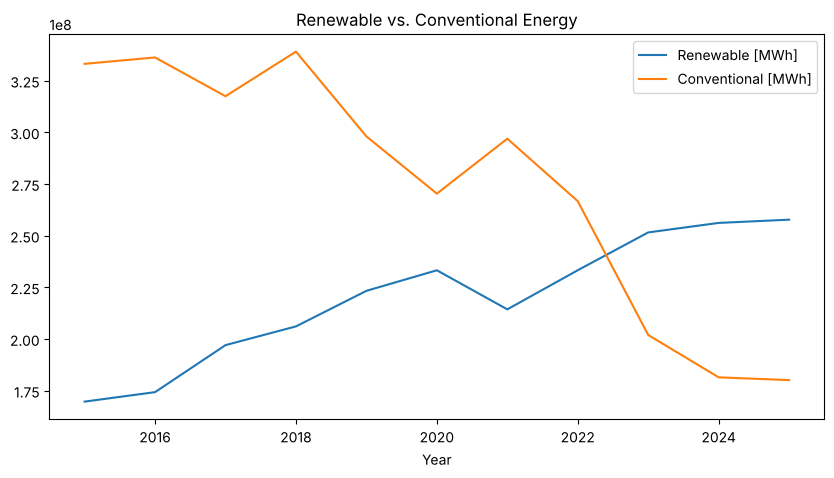

In [16]:
df_yearly["Renewable [MWh]"] = df_yearly[RENEWABLE_COLUMNS].sum(axis=1)
df_yearly["Conventional [MWh]"] = df_yearly[CONVENTIONAL_COLUMNS].sum(axis=1)

df_yearly.set_index("Year")[["Renewable [MWh]", "Conventional [MWh]"]].plot(figsize=(10, 5), title="Renewable vs. Conventional Energy")
plt.show()

Between 2015 - 2025, renewable energy is increasing while conventional energy is dropping.

# 3. Data Source: SMARD API

Instead of downloading the csv-file manually from smard.de, the data can also be fetched directly from the SMARD API with the script `src/fetch_smard_data.py`. The API delivers the same energy sources as numbers (no German number format) and already includes the newest published months.

To make sure the API delivers the same data as the manual export, both datasets are compared for the observation period 2015 - 2025.

In [17]:
from clean_smard_data import clean_smard_api
from config import START_YEAR, END_YEAR

df_api = clean_smard_api("../data/raw/smard_generation_monthly.csv")
print("Months in the API data:", len(df_api), "(", df_api["Date"].min().date(), "to", df_api["Date"].max().date(), ")")

df_api = df_api[(df_api["Year"] >= START_YEAR) & (df_api["Year"] <= END_YEAR)].reset_index(drop=True)
#Only the observation period is compared

Months in the API data: 142 ( 2015-01-01 to 2026-10-01 )


In [18]:
print("Same months in both datasets:", df_api["Date"].equals(df["Date"]))

difference = (df_api[ENERGY_COLUMNS] - df[ENERGY_COLUMNS]).abs().max()
print("Largest difference per energy source [MWh]:")
difference

Same months in both datasets: True
Largest difference per energy source [MWh]:


Biomass [MWh]               0.0
Hydropower [MWh]            0.0
Wind Offshore [MWh]         0.0
Wind Onshore [MWh]          0.0
Photovoltaics [MWh]         0.0
Other Renewables [MWh]      0.0
Nuclear [MWh]               0.0
Lignite [MWh]               0.0
Hard Coal [MWh]             0.0
Natural Gas [MWh]           0.0
Pumped Storage [MWh]        0.0
Other Conventional [MWh]    0.0
dtype: float64

The processed data used in the analysis notebook is created from the API data with two commands (run from the project folder):

```bash
python src/fetch_smard_data.py   # downloads the newest data into data/raw/
python src/clean_smard_data.py   # cleans it and saves data/processed/energy_generation_clean.csv
```

# 4. Summary

With the clean up script, the data is now more comprehensive, consistent and usable. First insights were made: The tendency seems to be that renewable energy should become the main producer. Events like for example the Fukushima catastrophe had an impact on nuclear energy which led to complete phase out after April 2023. These patterns and the impact of other events will be explored in more depth in the analysis notebook. 